# 10 — Is $83 reasonable next to SpaceX? And what breakthrough is the price betting on?

**Question:** Anthropic priced at $83 on Nov 18, 2026. SpaceX, 2026's other trillion-dollar IPO, trades at $143.50 ($1.95T). On the multiples investors quote, is Anthropic dear or cheap next to SpaceX? How much of each price do our cash-flow valuations explain, and what chance of a world-changing breakthrough is the rest betting on? If you believe in the breakthrough, how much of a portfolio does Anthropic at $83 deserve?

**Short answer**
1. **On revenue multiples, Anthropic is the cheaper stock.** Enterprise value is **24x** trailing revenue on shares outstanding (35x fully diluted), against SpaceX's **59x**; on Q3 revenue × 4, **13x** (18x) against **33x**. Anthropic's revenue grew **12.3x** in a year; SpaceX's grew 2.6x, mostly by buying xAI and Cursor. Neither makes real money yet. Anthropic's **+$3.0B** of trailing free cash flow is mostly interest on investors' cash; charge stock comp and it's **−$6.0B**. SpaceX's is **−$40B** (−$46B on the same basis) (§1, `10_multiples_vs_spacex.png`).
2. **Our DCFs explain ~84% of Anthropic's price and a sixth of SpaceX's.** Anthropic at $83 is **1.2x** the average of 08's 20,000 worlds ($69): $1.14T of business, $0.22T unexplained. On Anthropic's own compute contracts (09 §6), the business is worth ~$18–45 a share: $0.29–0.74T, leaving **$0.61–1.07T** unexplained. We re-valued the SpaceX post's forecasts on 08's rules: today's balance sheet, Cursor at its $60B deal price, stock comp as a cost and a CAPM rate of 8.9%. That doubles its value to **$23.64** (from $11.87). SpaceX at $143.50 is **6.1x** that: $0.32T of business, $1.63T unexplained (§2, `10_price_vs_dcf.png`).
3. **If the unexplained part is a ticket on a $10T breakthrough** (AGI, a cancer cure, a room-temperature superconductor), $83 implies a **~2% chance** that Anthropic wins it on our forecast (~4% against the median world), and **~6–11%** on its own contracts. SpaceX's price implies **~16%**: 7x our forecast's figure, and still 1.5–2.7x the contracts view's. On the SpaceX post's cruder method (whole valuation ÷ $10T) it's 14% vs 19% (§3).
4. **Kelly sizing:** at $83, Anthropic only deserves a place in a portfolio if you put the breakthrough above **~2.2%**, which is just the market's implied chance. At 5% the growth-optimal position is **~11%** of the portfolio (half-Kelly ~6%); at 10%, ~26%. If the $10T arrives around 2035 (worth ~$4T today), you need **~5.5%** before buying at all. On the contracts view the break-even is **~6% (Q2 efficiency) to ~11% (Q3)** (§4, `10_kelly.png`).

**Reading:** next to SpaceX, $83 looks reasonable, even cheap: lower multiples, faster growth, a fraction of the cash burn, and a smaller leap of faith. That's mostly a statement about SpaceX. On its own terms, with 06's 30–55% share of AI, $83 needs a top-third outcome for the business (08, 09) or about a 1-in-45 chance of a $10T breakthrough (1-in-9 to 1-in-16 on the company's own contracts). With the earlier 15–35% share it needed a top-eighth outcome or a 1-in-16 chance, so this conclusion rests on the share range. Even on the contracts view, SpaceX asks for higher odds.

| § | Question | Chart |
|---|---|---|
| 1 | On the usual multiples, is Anthropic at $83 priced above or below SpaceX? | `10_multiples_vs_spacex.png` |
| 2 | How far is each price above our own DCF, and what is the rest paying for? | `10_price_vs_dcf.png` |
| 3 | What chance of a world-changing breakthrough does each price imply? | — |
| 4 | If you believe in the prize, how much of a portfolio should go into Anthropic at $83? | `10_kelly.png` |

**Inputs:** `montecarlo.py` (08's 20,000 worlds; its new `prize_chance` / `prize_value` inputs, off by default), `data/valuation_inputs.csv` (IPO terms and price), `data/real_earnings.csv` (02), `source_docs/spacex/spcx_companyfacts.json` (SpaceX's XBRL data from EDGAR, cached, used to check the 10-Q numbers), the SpaceX post's segment forecasts (`../spacex_s1/analysis/dcf.py`, re-valued here).
**Outputs:** `data/comps_spacex.csv` (outside data: SpaceX price, shares, balance sheet, revenue, cash flow, Cursor deal value, industry betas, the post's DCF; each with `as_of`, `source_url`, `reliability`); three charts.

**How to read this notebook.** Data are in $ millions; charts and prose in $ billions or trillions, per-share figures in dollars. Anthropic's Q3 ends Sep 30, 2026, like SpaceX's latest 10-Q. Prices are as of Nov 18, 2026.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import *
import montecarlo as mc

B, T = 1000, 1e6                                                       # $M -> $B, $T
X = load('valuation_inputs').set_index('item').value                   # 08: IPO terms and price
R = wide(load('real_earnings'), index='metric')                         # 02: Anthropic revenue and FCF
price = mc.IPO_PRICE

# Outside data: SpaceX (Nasdaq: SPCX). Not from Anthropic's S-1, kept out of the reconciliation checks.
Q10 = 'https://www.sec.gov/Archives/edgar/data/1181412/000162828026066880/spcx-20260930.htm'   # 10-Q, Sep 30 2026
S1 = 'https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany&CIK=0001181412&type=S-1'      # S-1 (FY2025), via ../spacex_s1
CURSOR = 'https://www.sec.gov/Archives/edgar/data/1181412/000162828026056945/spcx-20260814.htm'  # 8-K, Cursor merger closed
BETAS = 'https://pages.stern.nyu.edu/~adamodar/New_Home_Page/datafile/Betas.html'               # same table as 08's betas
POST = 'goodatinvesting.com SpaceX IPO post (../spacex_s1/blog_post.md)'
OUTSIDE = [  # (item, value, unit, as_of, source_url, reliability, note)
    ('price', 143.50, 'usd_per_share', '2026-11-18', 'https://www.heygotrade.com/en/news/spacex-spcx-stock-news-november-19-2026/', 'market',
     'Nov 18 close, the day Anthropic priced at $83 (same-day comparison); $1.949T market cap. Nov 19 intraday ~$137-139 (-3 to -5%)'),
    ('ipo_price', 135.00, 'usd_per_share', '2026-06-03', 'https://www.cnbc.com/2026/06/03/spacex-ipo-stock-price-roadshow-musk.html', 'press', 'priced Jun 3 2026, $1.77T'),
    ('shares_outstanding', 13581.063709, 'millions_shares', '2026-10-15', Q10, 'primary', '10-Q cover: Class A 8,246,541,218 + Class B 5,334,522,491'),
    ('cash', 51294, 'millions_usd', '2026-09-30', Q10, 'primary', 'cash and cash equivalents'),
    ('marketable_securities', 38561, 'millions_usd', '2026-09-30', Q10, 'primary', 'current; mostly government securities'),
    ('debt', 38844, 'millions_usd', '2026-09-30', Q10, 'primary', 'long-term debt and finance leases, incl. current portion'),
    ('revenue_q3_2026', 14575, 'millions_usd', '2026-09-30', Q10, 'primary', 'includes xAI (merged Feb 2 2026) and Cursor (from Aug 14 2026)'),
    ('revenue_q3_2025', 5576, 'millions_usd', '2025-09-30', Q10, 'primary', 'comparative column'),
    ('revenue_si_q3_2026', 7560, 'millions_usd', '2026-09-30', Q10, 'primary', 'SI (formerly AI) segment'),
    ('revenue_si_q3_2025', 813, 'millions_usd', '2025-09-30', Q10, 'primary', 'SI (formerly AI) segment'),
    ('revenue_si_advertising_q3_2026', 538, 'millions_usd', '2026-09-30', Q10, 'primary', 'SI segment: Advertising (X)'),
    ('revenue_si_solutions_q3_2026', 7022, 'millions_usd', '2026-09-30', Q10, 'primary',
     'SI Solutions & Infrastructure: Grok, Cursor and X subscriptions, data licensing, Grok API, and the sale of cloud services'),
    ('customer_b_pct_q3_2026', 34.5, 'pct', '2026-09-30', Q10, 'primary',
     'Concentration of risk: Customer B 34.5% of consolidated Q3 revenue (24.2% of 9M; <10% in 2025), all in the SI segment. Unnamed; our inference: Anthropic (SpaceXAI compute, S-1 ~$3.1B/month at full capacity)'),
    ('revenue_connectivity_q3_2026', 5248, 'millions_usd', '2026-09-30', Q10, 'primary', 'Starlink'),
    ('revenue_connectivity_q3_2025', 3097, 'millions_usd', '2025-09-30', Q10, 'primary', 'Starlink'),
    ('revenue_9m_2026', 27083, 'millions_usd', '2026-09-30', Q10, 'primary', ''),
    ('revenue_9m_2025', 13714, 'millions_usd', '2025-09-30', Q10, 'primary', ''),
    ('revenue_fy2025', 18674, 'millions_usd', '2025-12-31', S1, 'primary', ''),
    ('cfo_9m_2026', 13097, 'millions_usd', '2026-09-30', Q10, 'primary', 'net cash from operating activities'),
    ('cfo_9m_2025', 4120, 'millions_usd', '2025-09-30', Q10, 'primary', ''),
    ('cfo_fy2025', 6785, 'millions_usd', '2025-12-31', S1, 'primary', ''),
    ('capex_9m_2026', 48069, 'millions_usd', '2026-09-30', Q10, 'primary', 'purchases of property, plant and equipment'),
    ('capex_9m_2025', 13846, 'millions_usd', '2025-09-30', Q10, 'primary', ''),
    ('capex_fy2025', 20737, 'millions_usd', '2025-12-31', S1, 'primary', ''),
    ('sbc_9m_2026', 3833, 'millions_usd', '2026-09-30', Q10, 'primary', 'share-based compensation (cash flow statement)'),
    ('sbc_9m_2025', 1044, 'millions_usd', '2025-09-30', Q10, 'primary', ''),
    ('sbc_fy2025', 1947, 'millions_usd', '2025-12-31', S1, 'primary', ''),
    ('interest_income_9m_2026', 1426, 'millions_usd', '2026-09-30', Q10, 'primary', 'interest income on cash and securities'),
    ('interest_income_9m_2025', 370, 'millions_usd', '2025-09-30', Q10, 'primary', ''),
    ('interest_income_fy2025', 492, 'millions_usd', '2025-12-31', S1, 'primary', ''),
    ('lease_principal_9m_2026', 270, 'millions_usd', '2026-09-30', Q10, 'primary', 'principal repayments on finance leases'),
    ('lease_principal_9m_2025', 213, 'millions_usd', '2025-09-30', Q10, 'primary', ''),
    ('lease_principal_fy2025', 295, 'millions_usd', '2025-12-31', S1, 'primary', ''),
    ('cursor_deal_value', 60000, 'millions_usd', '2026-08-14', CURSOR, 'primary', '389,289,254 Class A shares at an implied $60B equity value; all stock, closed Aug 14 2026'),
    ('beta_aerospace_defense', 0.87, 'x', '2026-01-01', BETAS, 'primary', 'Damodaran, Aerospace/Defense, 79 firms, unlevered beta corrected for cash'),
    ('beta_telecom_wireless', 0.39, 'x', '2026-01-01', BETAS, 'primary', 'Damodaran, Telecom (Wireless), 12 firms, unlevered beta corrected for cash'),
    ('dcf_base', 7.23, 'usd_per_share', '2026-06-03', POST, 'ours', 'base case: 12% WACC, 12.5B pro-forma shares'),
    ('dcf_base_with_floor', 11.87, 'usd_per_share', '2026-06-03', POST, 'ours', 'base case, AI segment floored at zero (it can be shut down)'),
]
S = pd.DataFrame(OUTSIDE, columns=['item', 'value', 'unit', 'as_of', 'source_url', 'reliability', 'note'])
S.to_csv(DATA / 'comps_spacex.csv', index=False)
S = S.set_index('item').value

# Check the 10-Q numbers against EDGAR's XBRL data (cached in source_docs/spacex/)
facts = json.load(open('source_docs/spacex/spcx_companyfacts.json'))['facts']['us-gaap']
def xbrl(tag, end, start=None):
    return next(a['val'] for a in facts[tag]['units']['USD'] if a['end'] == end and a.get('start') == start) / 1e6
REV, CFO, PPE = 'RevenueFromContractWithCustomerExcludingAssessedTax', 'NetCashProvidedByUsedInOperatingActivities', 'PaymentsToAcquirePropertyPlantAndEquipment'
assert S.cash == xbrl('CashAndCashEquivalentsAtCarryingValue', '2026-09-30')
assert S.marketable_securities == xbrl('MarketableSecuritiesCurrent', '2026-09-30')
assert S.debt == xbrl('LongTermDebtAndCapitalLeaseObligationsIncludingCurrentMaturities', '2026-09-30')
assert S.revenue_q3_2026 == xbrl(REV, '2026-09-30', '2026-07-01') and S.revenue_q3_2025 == xbrl(REV, '2025-09-30', '2025-07-01')
assert S.revenue_9m_2026 == xbrl(REV, '2026-09-30', '2026-01-01') and S.revenue_9m_2025 == xbrl(REV, '2025-09-30', '2025-01-01')
assert S.cfo_9m_2026 == xbrl(CFO, '2026-09-30', '2026-01-01') and S.capex_9m_2026 == xbrl(PPE, '2026-09-30', '2026-01-01')
for item, tag in [('sbc', 'ShareBasedCompensation'), ('interest_income', 'InvestmentIncomeInterest'), ('lease_principal', 'FinanceLeasePrincipalPayments')]:
    assert S[f'{item}_9m_2026'] == xbrl(tag, '2026-09-30', '2026-01-01') and S[f'{item}_9m_2025'] == xbrl(tag, '2025-09-30', '2025-01-01')
assert abs(S.price * S.shares_outstanding / 1e6 - 1.949) < 0.001, 'quoted market cap and 10-Q share count disagree'
S

item
price                               143.500000
ipo_price                           135.000000
shares_outstanding                13581.063709
cash                              51294.000000
marketable_securities             38561.000000
debt                              38844.000000
revenue_q3_2026                   14575.000000
revenue_q3_2025                    5576.000000
revenue_si_q3_2026                 7560.000000
revenue_si_q3_2025                  813.000000
revenue_si_advertising_q3_2026      538.000000
revenue_si_solutions_q3_2026       7022.000000
customer_b_pct_q3_2026               34.500000
revenue_connectivity_q3_2026       5248.000000
revenue_connectivity_q3_2025       3097.000000
revenue_9m_2026                   27083.000000
revenue_9m_2025                   13714.000000
revenue_fy2025                    18674.000000
cfo_9m_2026                       13097.000000
cfo_9m_2025                        4120.000000
cfo_fy2025                         6785.000000
capex_9m

## 1. On the usual multiples, is Anthropic at $83 priced above or below SpaceX?
**Why ask:** SpaceX is the only other trillion-dollar IPO of 2026, and like Anthropic it sells a story bigger than its cash flows (its AI arm, xAI and Cursor). If Anthropic looks cheap next to SpaceX, "$83 is reasonable" has a market-based argument.

**Method:** the multiple a growth investor quotes is **enterprise value ÷ revenue**. Enterprise value (EV) is what the market pays for the business itself: market value of the shares, minus the cash it would come with, plus the debt it would come with. Two revenue yardsticks: the **last twelve months** (Q4-2025 to Q3-2026, from the filings), and **Q3 × 4**, the latest quarter's run-rate. Both companies' last reported quarter ends Sep 30, 2026.

**Share counts have to match.** SpaceX's $1.949T is its 13.58B shares *outstanding* × $143.50; stock options and unvested RSUs aren't in it. The like-for-like Anthropic number is its shares outstanding after the IPO: the S-1/A's 13.09B at $74, re-priced at $83 (the $26B placement buys fewer shares), plus the 155M extra base shares added at pricing (assumed all new; the final prospectus will say). Our usual **fully diluted** count (16.4B today + IPO shares, 08) is shown too; it's the one per-share values use, and it makes Anthropic look more expensive.

**Cash:** Anthropic's Sep-30 cash and short-term investments plus the IPO's net proceeds at $83 (underwriting costs at the S-1/A's implied ~1.2% rate). The convertible notes turn into shares at the IPO, so there's no debt. SpaceX: cash plus marketable securities, minus debt and finance leases.

**Free cash flow, on 02's definitions for both.** **FCF** = operating cash flow − capex − finance-lease principal (for Anthropic, also prepayments for leased equipment). It flatters both companies: operating cash flow counts interest earned on cash raised from investors, and adds back stock comp because it isn't paid in cash. **Owner FCF** takes both out (and Anthropic's share-paid donations): what's left if those costs were paid in cash.

In [2]:
# Anthropic after the IPO, at $83 (underwriters' option not exercised), final prospectus
placement = X['ipo_private_placement']
company_shares = X['ipo_shares_offered_company']                                # millions, sold by Anthropic
proceeds = X['ipo_net_proceeds']                                                # $M, offering + placement, after fees
cash_a = mc.CASH + proceeds
out_a = X['ipo_shares_outstanding_after']                                       # Class A + N outstanding after the offering
fd_a = mc.FD_SHARES / 1e6 + company_shares + placement / price
q = ['Q4-2025', 'Q1-2026', 'Q2-2026', 'Q3-2026']

# SpaceX, trailing twelve months = FY2025 - 9M-2025 + 9M-2026
ttm = lambda item: S[f'{item}_fy2025'] - S[f'{item}_9m_2025'] + S[f'{item}_9m_2026']
rows = {
    'Anthropic (shares outstanding)': dict(price=price, shares_m=out_a, cash=cash_a, debt=0.0),
    'Anthropic (fully diluted)': dict(price=price, shares_m=fd_a, cash=cash_a + mc.STRIKE_PROCEEDS, debt=0.0),
    'SpaceX (shares outstanding)': dict(price=S.price, shares_m=S.shares_outstanding, cash=S.cash + S.marketable_securities, debt=S.debt),
}
anth = dict(ttm_revenue=R.loc['revenue', q].sum(), run_rate=R.loc['revenue', 'Q3-2026'] * 4,
            growth=R.loc['revenue', 'Q3-2026'] / R.loc['revenue', 'Q3-2025'] - 1,
            ttm_fcf=R.loc['fcf', 'TTM-2026-09'], ttm_owner_fcf=R.loc['owner_fcf', 'TTM-2026-09'])
spcx = dict(ttm_revenue=ttm('revenue'), run_rate=S.revenue_q3_2026 * 4, growth=S.revenue_q3_2026 / S.revenue_q3_2025 - 1,
            ttm_fcf=ttm('cfo') - ttm('capex') - ttm('lease_principal'))                # 02's FCF; SpaceX has no equipment prepayments line
spcx['ttm_owner_fcf'] = spcx['ttm_fcf'] - ttm('interest_income') - ttm('sbc')          # 02's owner FCF (SpaceX gives no share-paid donations)
M = pd.DataFrame(rows).T
for k in anth:
    M[k] = [anth[k], anth[k], spcx[k]]
M['market_cap'] = M.price * M.shares_m
M['ev'] = M.market_cap - M.cash + M.debt
M['ev_ttm_revenue'] = M.ev / M.ttm_revenue
M['ev_run_rate'] = M.ev / M.run_rate
M['ttm_fcf_margin'] = M.ttm_fcf / M.ttm_revenue
M['ttm_owner_fcf_margin'] = M.ttm_owner_fcf / M.ttm_revenue
print(f'IPO net proceeds at ${price:.0f}: ${proceeds/B:.1f}B; Anthropic cash after the IPO ${cash_a/B:.0f}B')
show = M.assign(**{c: M[c] / B for c in ['shares_m', 'cash', 'debt', 'ttm_revenue', 'run_rate', 'ttm_fcf', 'ttm_owner_fcf', 'market_cap', 'ev']})
show.rename(columns={'shares_m': 'shares, B', 'cash': 'cash, $B', 'debt': 'debt, $B', 'ttm_revenue': 'revenue TTM, $B',
                     'run_rate': 'Q3 x 4, $B', 'growth': 'Q3 yoy growth', 'ttm_fcf': 'FCF TTM, $B', 'ttm_owner_fcf': 'owner FCF TTM, $B', 'market_cap': 'market cap, $B',
                     'ev': 'EV, $B'}).T.round(2)

IPO net proceeds at $83: $104.8B; Anthropic cash after the IPO $237B


,Anthropic (shares outstanding),Anthropic (fully diluted),SpaceX (shares outstanding)
price,83.00,83.00,143.50
"shares, B",13.22,17.65,13.58
"cash, $B",236.64,241.81,89.86
"debt, $B",0.00,0.00,38.84
"revenue TTM, $B",35.28,35.28,32.04
"Q3 x 4, $B",67.82,67.82,58.30
Q3 yoy growth,11.27,11.27,1.61
"FCF TTM, $B",2.96,2.96,-39.55
"owner FCF TTM, $B",-6.04,-6.04,-45.83
"market cap, $B",1097.23,1464.71,1948.88


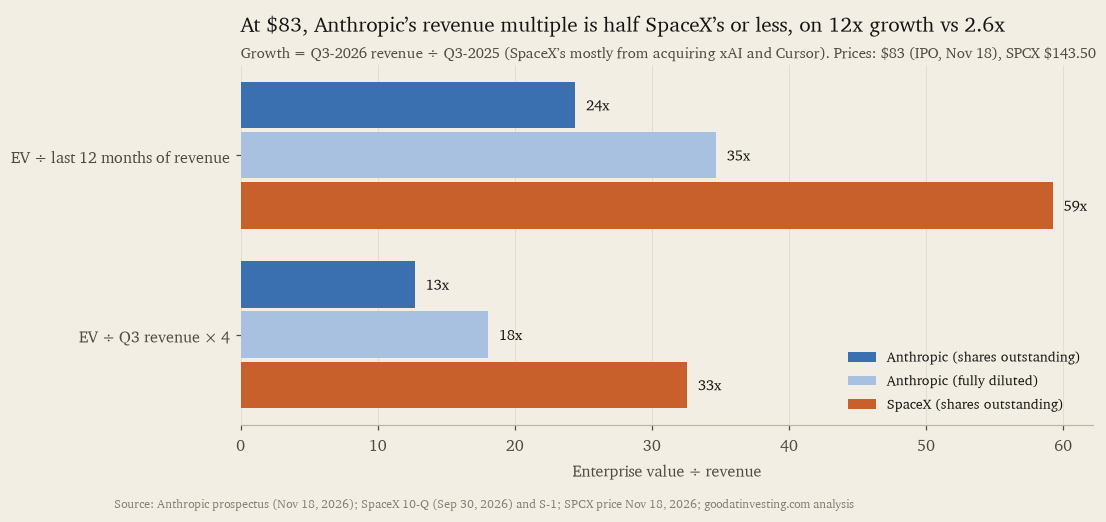

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.6))
metrics = [('ev_ttm_revenue', 'EV ÷ last 12 months of revenue'), ('ev_run_rate', 'EV ÷ Q3 revenue × 4')]
names = list(M.index)
colors = [SERIES[0], LIGHT, SERIES[1]]                                      # Anthropic outstanding / fully diluted / SpaceX
h = 0.26
for i, (m, label) in enumerate(metrics):
    for j, name in enumerate(names):
        y = i + (j - 1) * (h + 0.02)
        v = M.loc[name, m]
        ax.barh(y, v, height=h, color=colors[j], label=name if i == 0 else None)
        ax.text(v + 0.8, y, f'{v:.0f}x', va='center', fontsize=9.5, color=INK)
ax.set_yticks(range(len(metrics)), [l for _, l in metrics])
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.set_xlabel('Enterprise value ÷ revenue')
ax.legend(loc='lower right', fontsize=9)
g_a, g_s = M.growth.iloc[0], M.growth.iloc[2]
ax.set_title(f'At ${price:.0f}, Anthropic’s revenue multiple is half SpaceX’s or less, on {1 + g_a:.0f}x growth vs {1 + g_s:.1f}x')
subtitle(ax, f'Growth = Q3-2026 revenue ÷ Q3-2025 (SpaceX’s mostly from acquiring xAI and Cursor). Prices: ${price:.0f} (IPO, Nov 18), SPCX ${S.price:.2f}')
source(fig, 'Source: Anthropic prospectus (Nov 18, 2026); SpaceX 10-Q (Sep 30, 2026) and S-1; SPCX price Nov 18, 2026; goodatinvesting.com analysis')
fig.subplots_adjust(bottom=0.17)
save(fig, '10_multiples_vs_spacex.png')
plt.show()

**What this shows** (`10_multiples_vs_spacex.png`):
- **Anthropic is cheaper on every cut.** EV ÷ trailing revenue: **24x** (shares outstanding) or **35x** (fully diluted) vs SpaceX's **59x**. On Q3 × 4: **13x** or **18x** vs **33x**. Even our harsher fully diluted count, which SpaceX's figure doesn't use, leaves Anthropic at roughly half SpaceX's multiple.
- **And it grows much faster.** Anthropic's Q3 revenue was **12.3x** a year earlier. SpaceX's was 2.6x, but most of that is acquisitions: its AI segment went from $0.8B to $7.6B a quarter after merging with xAI (Feb 2) and buying Cursor (Aug 14). Starlink, the organic engine, grew **69%**.
- **Neither makes real money yet, but Anthropic is close.** Its free cash flow over the last twelve months was **+$3.0B** (8% of revenue). That's 02's standard measure, and it's flattered: $2.6B of it is interest on the cash investors put in, and $3.8B of stock comp is added back. Owner FCF, with both taken out (and donations), is **−$6.0B** (−17% of revenue). SpaceX's FCF was **−$40B**: $55B of capital spending against $16B from operations. Its owner FCF is **−$46B** (−143% of revenue). Anthropic rents most of its compute through take-or-pay contracts (03, 06), so its version of SpaceX's capex is in its operating costs and its $895B of commitments.
- **Anthropic's cash is a big part of its price.** After the IPO it holds ~$237B, about a fifth of its $1.1T market cap on shares outstanding, so EV is well below market cap. SpaceX's ~$90B of cash and securities is mostly offset by $39B of debt.

On multiples alone, $83 is easy to defend next to SpaceX. Multiples compare two prices, though, and both could be high.

**Next:** measure each price against its own cash flows.

## 2. How far is each price above our own DCF, and what is the rest paying for?
**Why ask:** multiples compare two prices with each other. Both could be too high. Each post also has its own discounted cash flow (DCF) value: 08's for Anthropic, the SpaceX post's for SpaceX. The gap between price and DCF is the part of the price the business's forecast cash flows don't cover: the market's bet on something bigger.

**Method:** per share, price minus DCF value, times shares, is the **unexplained value** in dollars. For Anthropic we use the *average* of 08's 20,000 worlds, not the median: a price should reflect every outcome weighted by its odds, and the few huge worlds pull the average up (~$69 vs the ~$59 median). We also value Anthropic on **its own compute contracts** (09 §6, `mc.contract_worlds()`): the revenue its signed compute can serve at Q3-2026's and Q2-2026's efficiency, valued on the same rules. That's the conservative anchor: the only forecast the company has put money behind. We value Anthropic on today's 16.4B fully diluted shares, as 08 does: new IPO shares come with their own cash, so they don't change value per share. For SpaceX we start from the SpaceX post's segment forecasts (Bear/Base/Bull for Starlink, launch and AI, in `../spacex_s1/analysis/dcf.py`) and re-value them on 08's rules, one change at a time:
1. **Today's balance sheet and shares.** The post valued the company before its IPO: $14B of net debt on 12.5B shares. On Sep 30 SpaceX had **$51B of net cash** (IPO money included) and 13.58B shares. Cash flows start in Q4-2026; Jan–Sep's spending is already in that balance sheet. Each year's cash flow arrives mid-year, as in 08.
2. **Cursor, at its $60B deal price.** The post predates the deal, so its forecasts have no Cursor in them. SpaceX paid entirely in stock (389M shares, already in the 13.58B), so we add Cursor's value as what SpaceX paid for it, i.e. we assume it paid a fair price. Forecasting Cursor properly needs the 10-Q's acquisition note, which we haven't extracted.
3. **Stock comp as a cost, 21% tax on profits:** 08's owner free cash flow. The post added stock comp back and assumed no tax. (08 adds back stock comp on grants already in its fully diluted count. SpaceX's 13.58B shares outstanding leave out unvested grants, so all its stock comp stays a cost.)
4. **08's discount-rate formula:** risk-free rate + beta × equity risk premium, with the same Treasury rate and premium. SpaceX's beta is the average of Damodaran's industry betas (same table as 08) weighted by Q3-2026 revenue: software for SI (AI, 1.25), wireless telecom for Starlink (0.39), aerospace for launch (0.87). The post used 12%.

The post's terminal value stays: 2030 cash flow at steady state (capex = depreciation) growing 3% forever, as in 08, but from 2030 rather than 08's 2040. "With floor" means, as in the post, that a segment worth less than zero gets shut down rather than kept (in practice, the AI arm); that's the value we use. "Without floor" keeps it.

IPO shares sold for cash don't change the *unexplained* dollars below, only the per-share ratio. So SpaceX on today's (post-IPO) count and Anthropic on 08's pre-IPO 16.4B still compare fairly.

In [4]:
# SpaceX post's forecasts, re-valued on 08's rules
import sys, warnings
sys.path.insert(0, str(Path.cwd().parent / 'spacex_s1'))
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    from analysis import dcf as sx
    ACT = sx._actuals()

def spacex_ev(scn, r, tax=0.0, charge_sbc=False, from_sep30=False, g=0.03):
    """EV by segment, $M. Defaults reproduce the post: year-end FY2026-30, stock comp added back, no tax."""
    t, w = (np.array([0.125, 0.75, 1.75, 2.75, 3.75]), np.array([0.25, 1, 1, 1, 1])) if from_sep30 else (np.arange(1, 6), np.ones(5))
    proj, ev = sx.project_segments(scn, ACT), {}
    term = sx.terminal_fcf(scn, proj)                              # steady state: capex = depreciation, stock comp added back
    for seg, f in proj.items():
        sbc = f.sbc * charge_sbc
        cf = f.fcf - sbc - tax * f.op.clip(lower=0)
        tcf = term[seg] - sbc.iloc[-1]
        tcf -= tax * max(tcf, 0)
        tv = tcf * (1 + g) / (r - g)
        tv = max(tv, 0) if seg == 'AI' else tv                    # post: a fleet that can't pay for its refresh isn't refreshed
        ev[seg] = (cf.values * w / (1 + r) ** t).sum() + tv / (1 + r) ** t[-1]
    return pd.Series(ev)

def per_share(ev, extra, shares):
    return pd.Series({'without floor': (ev.sum() + extra) / shares, 'with floor': (ev.clip(lower=0).sum() + extra) / shares})

mix = pd.Series({'SI': S.revenue_si_q3_2026, 'Connectivity': S.revenue_connectivity_q3_2026,
                 'Space': S.revenue_q3_2026 - S.revenue_si_q3_2026 - S.revenue_connectivity_q3_2026})
industry_beta = pd.Series({'SI': X['beta_software_system_app'], 'Connectivity': S.beta_telecom_wireless, 'Space': S.beta_aerospace_defense})
beta_s = (mix / mix.sum() * industry_beta).sum()
r_s = (X['risk_free_rate'] + beta_s * X['equity_risk_premium']) / 100
r_a = mc.run()['discount_rate']
now = S.cash + S.marketable_securities - S.debt + S.cursor_deal_value     # net cash + Cursor, $M
bridge = pd.DataFrame({
    'SpaceX post (Jun 2026, 12%)': per_share(spacex_ev('Base', 0.12), -sx.net_debt_from_csv(), sx.PROFORMA_SHARES_M),
    '1. Sep-30 balance sheet and shares': per_share(spacex_ev('Base', 0.12, from_sep30=True), now - S.cursor_deal_value, S.shares_outstanding),
    '2. + Cursor at $60B': per_share(spacex_ev('Base', 0.12, from_sep30=True), now, S.shares_outstanding),
    '3. + stock comp as a cost, 21% tax': per_share(spacex_ev('Base', 0.12, 0.21, True, True), now, S.shares_outstanding),
    f'4. + 08 rate formula, beta {beta_s:.2f}: {r_s:.2%}': per_share(spacex_ev('Base', r_s, 0.21, True, True), now, S.shares_outstanding),
}).T
assert np.allclose(bridge.iloc[0], [S.dcf_base, S.dcf_base_with_floor], atol=0.005), 'no longer reproduces the post'
sx_dcf, sx_dcf_low = bridge.iloc[-1]['with floor'], bridge.iloc[-1]['without floor']
scen = {scn: per_share(spacex_ev(scn, r_s, 0.21, True, True), now, S.shares_outstanding)['with floor'] for scn in ('Bear', 'Base', 'Bull')}
at_r_a = per_share(spacex_ev('Base', r_a, 0.21, True, True), now, S.shares_outstanding)
p26 = sx.project_segments('Base', ACT)
print(f"Bear / Base / Bull, with floor, at {r_s:.2%}: " + ' / '.join(f'${x:.2f}' for x in scen.values()))
print(f"Base at Anthropic's {r_a:.2%}: ${at_r_a['with floor']:.2f} with floor, ${at_r_a['without floor']:.2f} without")
print(f"Staleness check, post's Base for all of FY2026 vs the 10-Q's first nine months: revenue ${sum(f.rev.iloc[0] for f in p26.values())/B:.0f}B "
      f"vs ${S.revenue_9m_2026/B:.0f}B; capex ${sum(f.capex.iloc[0] for f in p26.values())/B:.0f}B vs ${S.capex_9m_2026/B:.0f}B")
bridge.round(2)

Bear / Base / Bull, with floor, at 8.88%: $14.45 / $23.64 / $31.73
Base at Anthropic's 10.45%: $19.94 with floor, $14.90 without
Staleness check, post's Base for all of FY2026 vs the 10-Q's first nine months: revenue $30B vs $27B; capex $18B vs $48B


,without floor,with floor
"SpaceX post (Jun 2026, 12%)",7.23,11.87
1. Sep-30 balance sheet and shares,13.03,17.66
2. + Cursor at $60B,17.45,22.08
"3. + stock comp as a cost, 21% tax",12.68,17.57
"4. + 08 rate formula, beta 0.89: 8.88%",18.45,23.64


**The bridge, in words.** The post's base case was worth **$7.23** a share, or **$11.87** with the AI arm shut down at zero. Each step's change:
1. **Today's balance sheet: +$5.79.** SpaceX now holds net cash instead of net debt, because its June IPO sold shares at $135, far above their DCF value, for cash.
2. **Cursor at its deal price: +$4.42.**
3. **Stock comp charged as a cost, plus tax: −$4.51.**
4. **The rate: +$6.07.** It falls from 12% to **8.9%**, because SpaceX's revenue-weighted beta is 0.89: Starlink's telecom-like business is less tied to the market than software.

**Result:** the updated base case is **$23.64** with the floor ($18.45 without). Bear and bull are $14.45 and $31.73. At Anthropic's own 10.45% rate it would be $19.94.

**The forecast itself is stale, and we haven't fixed that.** The post's base case expected ~$30B of revenue and ~$18B of capex for all of 2026. The 10-Q shows $27B of revenue and **$48B of capex** in the first nine months. The Sep-30 balance sheet absorbs what's already been spent, but from Q4 on we still use June's forecasts. More spending lowers the value unless revenue keeps pace. A full re-forecast belongs in the SpaceX project.

**Next:** set both DCFs against their prices.

In [5]:
base = mc.run()
v = base['worlds'].per_share
# 09 §6: what Anthropic's own compute contracts are worth (one fixed world per S-1 efficiency)
contracts = {f"Contracts {one['worlds'].rev_per_compute.iloc[0]:.2f}x": one['worlds'].per_share.iloc[0]
             for one in mc.contract_worlds().values()}
contracts = dict(sorted(contracts.items(), key=lambda kv: -kv[1]))   # higher value first
ant = ['Anthropic', *contracts]
dcf = pd.DataFrame({
    'price': [price] * len(ant) + [S.price],
    'dcf_per_share': [v.mean(), *contracts.values(), sx_dcf],
    'dcf_low': [v.median(), *contracts.values(), sx_dcf_low],         # Anthropic median; SpaceX base without the floor
    'shares_m': [mc.FD_SHARES / 1e6] * len(ant) + [S.shares_outstanding],
}, index=ant + ['SpaceX'])
dcf['price_over_dcf'] = dcf.price / dcf.dcf_per_share
dcf['business_value'] = dcf.dcf_per_share * dcf.shares_m                 # $M
dcf['unexplained'] = (dcf.price - dcf.dcf_per_share) * dcf.shares_m
dcf['unexplained_share'] = dcf.unexplained / (dcf.price * dcf.shares_m)
PRIZE = mc.PARAMS['prize_value']                                         # $10T, the SpaceX post's "AGI prize"
dcf['implied_prize_chance'] = dcf.unexplained / PRIZE
dcf['implied_prize_chance_low_dcf'] = (dcf.price - dcf.dcf_low) * dcf.shares_m / PRIZE
dcf.assign(business_value=dcf.business_value / T, unexplained=dcf.unexplained / T).rename(
    columns={'business_value': 'business value, $T', 'unexplained': 'unexplained, $T'}).round(3)

,price,dcf_per_share,dcf_low,shares_m,price_over_dcf,"business value, $T","unexplained, $T",unexplained_share,implied_prize_chance,implied_prize_chance_low_dcf
Anthropic,83.0,69.474,59.098,16377.505,1.195,1.138,0.222,0.163,0.022,0.039
Contracts 2.08x,83.0,45.480,45.480,16377.505,1.825,0.745,0.614,0.452,0.061,0.061
Contracts 1.72x,83.0,17.551,17.551,16377.505,4.729,0.287,1.072,0.789,0.107,0.107
SpaceX,143.5,23.645,18.451,13581.064,6.069,0.321,1.628,0.835,0.163,0.170


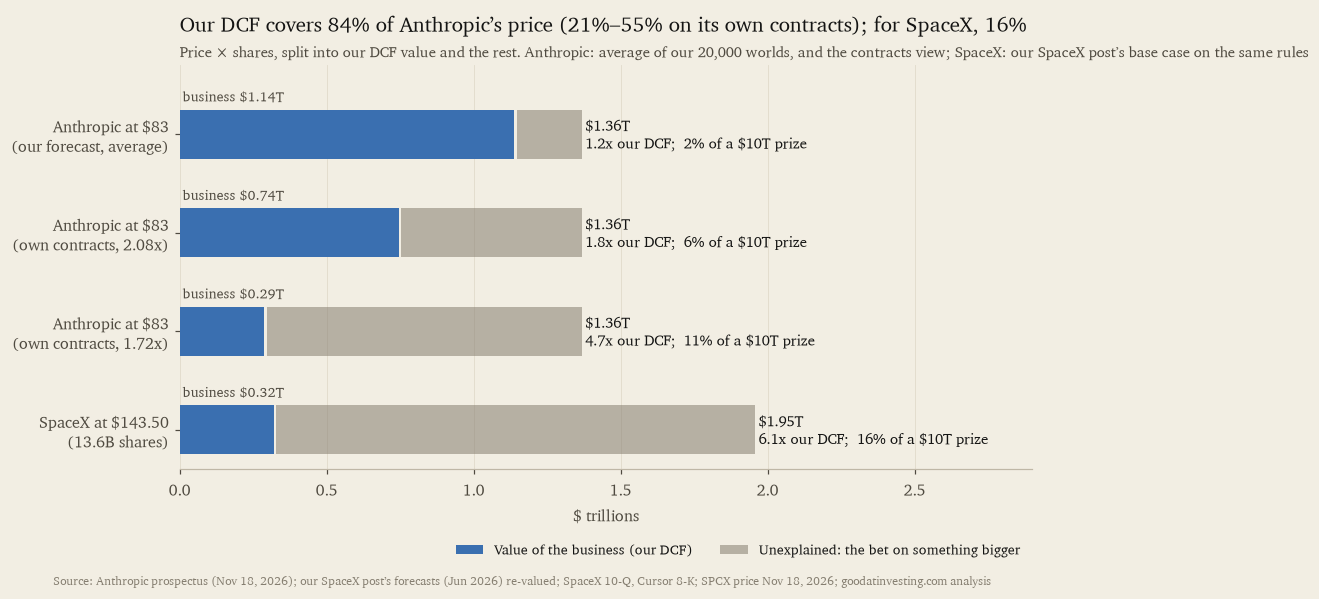

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.4))
for i, name in enumerate(dcf.index):
    biz, rest = dcf.loc[name, 'business_value'] / T, dcf.loc[name, 'unexplained'] / T
    ax.barh(i, biz, height=0.5, color=SERIES[0], label='Value of the business (our DCF)' if i == 0 else None)
    ax.barh(i, rest, left=biz + 0.008, height=0.5, color=NEUTRAL, alpha=0.55, label='Unexplained: the bet on something bigger' if i == 0 else None)
    ax.text(0.01, i - 0.3, f'business ${biz:.2f}T', ha='left', va='bottom', fontsize=9, color=INK2)
    ax.text(biz + rest + 0.02, i, f'${biz + rest:.2f}T\n{dcf.loc[name, "price_over_dcf"]:.1f}x our DCF;  '
            f'{dcf.loc[name, "implied_prize_chance"]:.0%} of a $10T prize', va='center', fontsize=9.5, color=INK)
names = {'Anthropic': f'Anthropic at ${price:.0f}\n(our forecast, average)',
         **{k: f'Anthropic at ${price:.0f}\n(own contracts, {k.split()[-1]})' for k in contracts},
         'SpaceX': f'SpaceX at ${S.price:.2f}\n(13.6B shares)'}
ax.set_yticks(range(len(dcf)), [names[n] for n in dcf.index])
ax.set_ylim(len(dcf) - 0.6, -0.7)                                                    # inverted, with room for the labels
ax.set_xlim(0, 2.9)
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.set_xlabel('$ trillions')
ax.legend(loc='lower right', fontsize=9, ncols=2, bbox_to_anchor=(1, -0.25))
cov = 1 - dcf.unexplained_share
ax.set_title(f'Our DCF covers {cov["Anthropic"]:.0%} of Anthropic’s price ({cov[list(contracts)].min():.0%}–{cov[list(contracts)].max():.0%} '
             f'on its own contracts); for SpaceX, {cov["SpaceX"]:.0%}')
subtitle(ax, 'Price × shares, split into our DCF value and the rest. Anthropic: average of our 20,000 worlds, and the contracts view; SpaceX: our SpaceX post’s base case on the same rules')
source(fig, 'Source: Anthropic prospectus (Nov 18, 2026); our SpaceX post’s forecasts (Jun 2026) re-valued; SpaceX 10-Q, Cursor 8-K; SPCX price Nov 18, 2026; goodatinvesting.com analysis')
fig.subplots_adjust(bottom=0.2)
save(fig, '10_price_vs_dcf.png')
plt.show()

**What this shows** (`10_price_vs_dcf.png`):
- **Anthropic at $83 is 1.2x our DCF.** The average world is worth ~$69 a share, so $1.14T of the $1.36T (on today's 16.4B shares) is the business 06 forecasts. The other **$0.22T (16%)** is unexplained. Against the median world ($59) it's 1.4x; against the company's own contracts (~$18–45, 09 §6) it's 1.8–4.7x, with $0.61–1.07T unexplained (the middle two bars).
- **SpaceX at $143.50 is 6.1x its updated DCF** ($23.64 with the AI arm floored at zero; 7.8x the $18.45 without). **$0.32T of $1.95T** is business; **$1.63T (84%)** is unexplained. Updating the post halved the gap, but most of SpaceX's price is still unexplained.
- **SpaceX's price has risen since its IPO** ($135 to $143.50, +6%), and its unexplained part has grown with it.

So the two prices aren't the same kind of bet. On our forecast, most of Anthropic's price is a business we can forecast, with a modest premium on top. On its own contracts, about half to four-fifths of the price is premium. SpaceX's price is mostly premium on either comparison: 84%.

**Next:** put a number on that premium. What chance of a breakthrough would justify it?

## 3. What chance of a world-changing breakthrough does each price imply?
**Why ask:** the SpaceX post read AI valuations as lottery tickets: if a breakthrough (call it AGI) is a **$10T prize**, a lab's valuation ÷ $10T is the market's implied chance that the lab wins it. That simple version treats the whole valuation as the ticket. With a DCF in hand we can do better: the business pays for part of the price, and only the **unexplained** part (§2) is the ticket.

**Method:** implied chance = unexplained value ÷ $10T. "Breakthrough" here means anything worth far more than selling AI to knowledge workers, which is what 06's revenue ceiling measures: AGI, a cancer cure, a room-temperature superconductor. $10T is the payoff *to shareholders*, in today's money. A $10T win in ~2035 discounted at 10.5% is only ~$4T today, so a $10T payoff in today's money means a much bigger prize later.

In [7]:
chance = pd.DataFrame({
    'whole valuation ÷ $10T (SpaceX post method)': dcf.price * dcf.shares_m / PRIZE,
    'unexplained ÷ $10T (vs DCF average; SpaceX with floor)': dcf.implied_prize_chance,
    'unexplained ÷ $10T (vs DCF median; SpaceX without floor)': dcf.implied_prize_chance_low_dcf,
}).T
chance['SpaceX ÷ Anthropic'] = chance.SpaceX / chance.Anthropic
pv_prize = PRIZE / (1 + base['discount_rate']) ** (2035 - 2026.75)
print(f'$10T paid in 2035, discounted at {base["discount_rate"]:.2%}: ${pv_prize/T:.1f}T today')
chance.round(3)

$10T paid in 2035, discounted at 10.45%: $4.4T today


,Anthropic,Contracts 2.08x,Contracts 1.72x,SpaceX,SpaceX ÷ Anthropic
whole valuation ÷ $10T (SpaceX post method),0.136,0.136,0.136,0.195,1.434
unexplained ÷ $10T (vs DCF average; SpaceX with floor),0.022,0.061,0.107,0.163,7.348
unexplained ÷ $10T (vs DCF median; SpaceX without floor),0.039,0.061,0.107,0.170,4.338


In [8]:
# Two checks on the comparison: what SpaceX's AI revenue is, and what the first trade implies
cust_b = S.customer_b_pct_q3_2026 / 100 * S.revenue_q3_2026                    # $M, Q3, all in SI
other_si = S.revenue_si_q3_2026 - cust_b
print(f"SpaceX SI segment, Q3-2026: ${S.revenue_si_q3_2026/B:.2f}B = Customer B ${cust_b/B:.2f}B ({cust_b/S.revenue_si_q3_2026:.0%}) "
      f"+ everything else ${other_si/B:.2f}B (of which X ads ${S.revenue_si_advertising_q3_2026/B:.2f}B)")
print(f"  x4: ~${S.revenue_si_q3_2026*4/B:.0f}B a year, of which ~${other_si*4/B:.0f}B is Grok, Cursor, X and every other customer")
first = X['ant_first_trade']
for name in ant:
    c = (first - dcf.loc[name, 'dcf_per_share']) * dcf.loc[name, 'shares_m'] / PRIZE
    print(f"First trade ${first:.2f}: implied chance vs {name} = {c:.1%} (at $83: {dcf.loc[name, 'implied_prize_chance']:.1%}); SpaceX {dcf.loc['SpaceX', 'implied_prize_chance']:.1%}")

SpaceX SI segment, Q3-2026: $7.56B = Customer B $5.03B (67%) + everything else $2.53B (of which X ads $0.54B)
  x4: ~$30B a year, of which ~$10B is Grok, Cursor, X and every other customer
First trade $111.50: implied chance vs Anthropic = 6.9% (at $83: 2.2%); SpaceX 16.3%
First trade $111.50: implied chance vs Contracts 2.08x = 10.8% (at $83: 6.1%); SpaceX 16.3%
First trade $111.50: implied chance vs Contracts 1.72x = 15.4% (at $83: 10.7%); SpaceX 16.3%


**What this shows:**
- **$83 implies a ~2% chance** (2.2% vs the average world; 3.9% vs the median) that Anthropic lands a $10T breakthrough for its shareholders. **SpaceX's price implies ~16%**, roughly **4–7x** Anthropic's, for a company whose AI arm (xAI plus Cursor) does ~$30B a year of revenue against Anthropic's ~$68B. **On the contracts view, Anthropic's implied chance is ~6% (Q2 efficiency) to ~11% (Q3)**: still below SpaceX's, by 1.5–2.7x.
- **The SpaceX post's simpler method shrinks the gap** (14% vs 19%, 1.4x), because it counts Anthropic's real business as part of the ticket. Netting out the business is fairer to the company with the bigger business.
- **The answer scales with the prize.** At $5T, the implied chances double (~4% and 33%). A $10T payoff around 2035 is worth only ~$4.4T today at 10.45%, so "$10T in today's money" is already generous.
- **Both can't be right at scale.** The labs' implied chances add up: Anthropic ~2–11%, SpaceX 16%, plus OpenAI and Google's own claims on the same prize. If there's one prize and it goes to one winner, the market is paying for more than 100% of it somewhere, or the prize is much bigger than $10T.

- **Most of SpaceX's "AI revenue" is renting GPUs to one customer.** SpaceX's 10-Q puts SI at $7.56B in Q3: $0.54B of X ads and $7.02B of "Solutions & Infrastructure", which bundles Grok, Cursor and X subscriptions, the Grok API *and the sale of cloud services*. One unnamed **Customer B** was 34.5% of SpaceX's whole Q3 revenue, ~$5.0B, all in SI: two-thirds of the segment. SpaceX doesn't name it; Anthropic's S-1 says it pays SpaceXAI up to ~$3.1B a month for NVIDIA compute once capacity is delivered in December, so Anthropic fits (our inference, not a filing). Strip it out and Grok, Cursor, X and everyone else is ~$2.5B a quarter, ~$10B a year. The prize SpaceX's price implies is a bet on that ~$10B, plus a landlord's cut of its customer's.
- **At the first trade, the contracts view nearly matches SpaceX.** ANT opened at $111.50 on Nov 19 (press), 34% above $83. Against the average world the implied chance goes from ~2.2% to ~6.9%; on the contracts view, from 6–11% to **11–15%**, against SpaceX's 16%. So the "Anthropic is priced more fairly" argument holds at $83 and on our forecast; at the opening trade it rests on our forecast being closer to right than the contracts. One day's open is a noisy price, and SpaceX's 16% uses its Nov 18 close.

**Next:** turn the implied chance into a decision. If you have your own estimate, how big should the position be?

## 4. If you believe in the prize, how much of a portfolio should go into Anthropic at $83?
**Why ask:** "a small chance of a huge payoff" is the classic setting for the **Kelly criterion**: the bet size that makes a bankroll grow fastest over many bets. Bet less and you grow slowly; bet more and the losses compound faster than the wins, and you go broke even when every bet has positive expected value. It gives a rational answer to "how big a position does this lottery ticket deserve?"

**Method:** each of 08's 20,000 worlds gets a second coin flip: with chance *p* the breakthrough lands and shareholders get $10T on top (`prize_chance` and `prize_value` in `montecarlo.py`, off by default). Buying at $83, the payoff in a world is its value ÷ $83. Values are already discounted at the return the market asks of a stock like this, so a payoff of 1.0 means "did as well as the index"; above 1 beat it, below lost to it. Put a fraction *f* of the portfolio in Anthropic and the rest in the index. Kelly picks the *f* that maximizes the average **log** of wealth:

$$\text{Kelly } f = \arg\max_f \; \text{average over worlds and coin flips of } \log\big(1 - f + f \times \text{value} / \$83\big)$$

No borrowing and no short selling, so *f* stays between 0 and 1. We compute it exactly from each world's two branches (prize or not) rather than flipping coins, so the curve is smooth. Kelly is famously aggressive. Practitioners bet **half-Kelly**, giving up a quarter of the growth for much less risk, and that's even more sensible here because our worlds measure our uncertainty about Anthropic, not a known set of odds.

In [9]:
def kelly(values, p, prize_per_share, price, fs=np.linspace(0, 1, 1001)):
    """Growth-optimal fraction: each world pays value/price, or (value + prize)/price with chance p. Index return = 1."""
    x0 = values[:, None] / price
    x1 = (values[:, None] + prize_per_share) / price
    with np.errstate(divide='ignore'):                # a $0 world at f = 1 is log(0) = -inf: correctly ruled out
        growth = ((1 - p) * np.log(1 - fs + fs * x0) + p * np.log(1 - fs + fs * x1)).mean(axis=0)
    return fs[growth.argmax()]

vals = v.values
prize_ps = PRIZE * 1e6 / mc.FD_SHARES                                                  # $/share if the prize lands
breakeven = (price - vals.mean()) / prize_ps                                             # where the average payoff = 1
chances = np.linspace(0, 0.20, 81)
curves = {f'Our forecast, ${pz/T:.0f}T prize': (vals, pz) for pz in (10e6, 4e6)}
curves.update({f'Own contracts {k.split()[-1]}, $10T prize': (np.array([x]), 10e6) for k, x in contracts.items()})
curves = {name: [kelly(vs, c, pz * 1e6 / mc.FD_SHARES, price) for c in chances] for name, (vs, pz) in curves.items()}
breakeven_contracts = {k: (price - x) / prize_ps for k, x in contracts.items()}
print('Break-even prize chance on the contracts view: ' + ', '.join(f'{k}: {b:.1%}' for k, b in breakeven_contracts.items()))
print(f'Prize per share ${prize_ps:.0f}; average world ${vals.mean():.2f}; break-even prize chance at ${price:.0f}: {breakeven:.1%}')

# Spot check with the module's own coin flips (5%)
alt = mc.run(prize_chance=0.05)['worlds']
print(f"mc.run(prize_chance=0.05): {alt.prize_hit.mean():.1%} of worlds hit; average value ${alt.per_share.mean():.2f}, median ${alt.per_share.median():.2f}")

table = pd.DataFrame({f'Kelly fraction, ${pz/T:.0f}T prize': [kelly(vals, c, pz * 1e6 / mc.FD_SHARES, price) for c in (0, .022, .05, .08, .10, .15, .20)]
                      for pz in (10e6, 4e6)}, index=pd.Index([0, .022, .05, .08, .10, .15, .20], name='prize chance'))
table['highest price with Kelly > 0, $10T'] = vals.mean() + table.index * prize_ps
for k, x in contracts.items():
    table[f'Kelly fraction, own contracts {k.split()[-1]}, $10T'] = [kelly(np.array([x]), p, prize_ps, price) for p in table.index]
table.round(3)

Break-even prize chance on the contracts view: Contracts 2.08x: 6.1%, Contracts 1.72x: 10.7%
Prize per share $611; average world $69.47; break-even prize chance at $83: 2.2%


mc.run(prize_chance=0.05): 4.9% of worlds hit; average value $99.66, median $62.38


,"Kelly fraction, $10T prize","Kelly fraction, $4T prize","highest price with Kelly > 0, $10T","Kelly fraction, own contracts 2.08x, $10T","Kelly fraction, own contracts 1.72x, $10T"
prize chance,,,,,
0.000,0.000,0.000,69.474,0.000,0.000
0.022,0.000,0.000,82.908,0.000,0.000
0.050,0.112,0.000,100.004,0.000,0.000
0.080,0.208,0.081,118.322,0.044,0.000
0.100,0.264,0.140,130.534,0.091,0.000
0.150,0.383,0.268,161.064,0.209,0.061
0.200,0.484,0.378,191.593,0.327,0.132


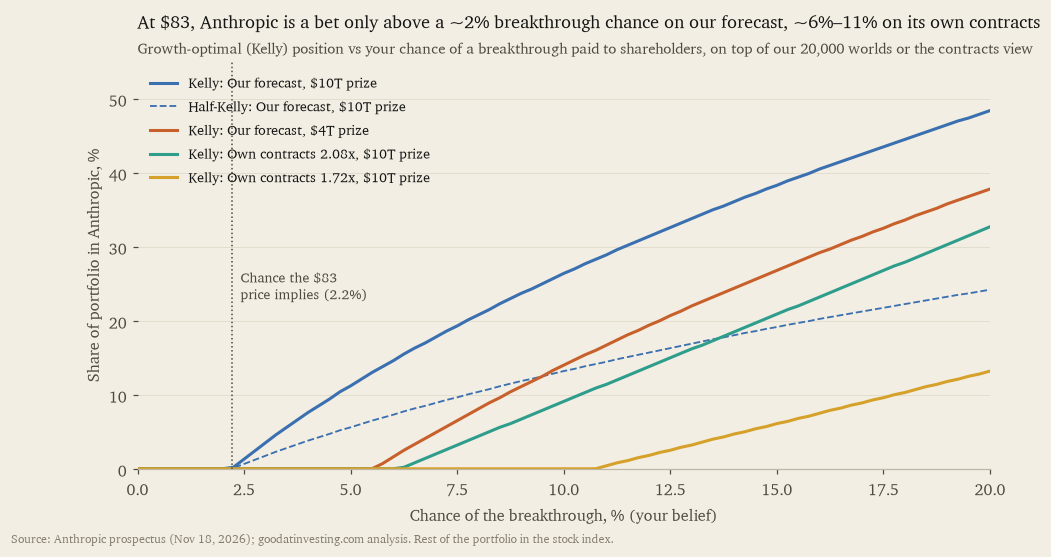

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
for (name, ys), col in zip(curves.items(), SERIES):
    ax.plot(chances * 100, np.array(ys) * 100, color=col, lw=2, label=f'Kelly: {name}')
    if name.startswith('Our forecast, $10T'):
        ax.plot(chances * 100, np.array(ys) * 50, color=col, lw=1.2, ls='--', label=f'Half-Kelly: {name}')
implied = dcf.loc['Anthropic', 'implied_prize_chance']
ax.axvline(implied * 100, color=INK2, lw=1, ls=':')
ax.text(implied * 100 + 0.2, 27, f'Chance the ${price:.0f}\nprice implies ({implied:.1%})', fontsize=9, color=INK2, va='top')
ax.set_xlim(0, 20)
ax.set_ylim(0, 55)
ax.set_xlabel('Chance of the breakthrough, % (your belief)')
ax.set_ylabel('Share of portfolio in Anthropic, %')
ax.legend(loc='upper left', fontsize=9)
ax.set_title(f'At ${price:.0f}, Anthropic is a bet only above a ~{breakeven:.0%} breakthrough chance on our forecast, '
             f'~{min(breakeven_contracts.values()):.0%}–{max(breakeven_contracts.values()):.0%} on its own contracts', fontsize=12)
subtitle(ax, 'Growth-optimal (Kelly) position vs your chance of a breakthrough paid to shareholders, on top of our 20,000 worlds or the contracts view')
source(fig, 'Source: Anthropic prospectus (Nov 18, 2026); goodatinvesting.com analysis. Rest of the portfolio in the stock index.')
fig.subplots_adjust(bottom=0.14)
save(fig, '10_kelly.png')
plt.show()

**What this shows** (`10_kelly.png`):
- **Below ~2.2%, the answer is zero.** That break-even is the market's implied chance from §3, by construction: at $83 the average payoff only beats the index if your breakthrough chance beats the market's. Without a prize, 08's worlds alone are worth $69 on average, and Kelly puts nothing in.
- **Above it, the position grows fast, then flattens.** With a $10T prize: 5% → **~11%** of the portfolio (half-Kelly ~6%), 10% → ~26%, 20% → ~48%.
- **The prize's timing matters.** If $10T arrives around 2035, it's worth ~$4T today, and the break-even rises to **~5.5%**. At 10% the position is ~14%.
- **On the contracts view (green and yellow lines), the bar is higher:** no position below ~6% (Q2 efficiency) or ~11% (Q3). At 10%, Kelly says ~9% of a portfolio at Q2 efficiency and nothing at Q3.
- **Turned around, as a maximum price:** for a buyer who thinks the chance is 5%, Anthropic is worth up to **~$100**; at 10%, ~$131 (the table's last column). With no prize at all, ~$69.

In short: whether $83 is reasonable depends on one number you have to supply, your chance of an economy-changing breakthrough. The market's is ~2% on our forecast, ~6–11% on the company's own contracts. Our cash-flow model can't tell you which number is right. It does tell you that below ~2% the stock isn't worth owning on these worlds, and the answer is very sensitive to 06's share range: at 15–35%, the break-even was ~6%. Kelly's full-size answers are large (~11% of a portfolio at 5%); half-Kelly or less is the sensible version, because our worlds measure our uncertainty, not known odds.

## Findings, by section
1. At $83, Anthropic trades at 24x (shares outstanding) or 35x (fully diluted) trailing revenue and 13–18x Q3 × 4, vs SpaceX's 59x and 33x. Anthropic grew 12.3x year on year; SpaceX 2.6x, mostly from acquisitions. Trailing FCF: Anthropic +$3.0B, but −$6.0B once interest and stock comp come out; SpaceX −$40B, or −$46B on the same basis.
2. Re-valuing the SpaceX post's base case on 08's rules (Sep-30 net cash, Cursor at $60B, stock comp and tax as costs, an 8.9% CAPM rate) takes it from $11.87 to $23.64. Our DCFs cover 84% of Anthropic's price ($1.14T of $1.36T; 1.2x), 21–55% on its own contracts ($0.29–0.74T), and 16% of SpaceX's ($0.32T of $1.95T; 6.1x).
3. If the rest is a ticket on a $10T breakthrough, $83 implies ~2% (our forecast) to ~6–11% (own contracts), and SpaceX ~16%. The whole-valuation method gives 14% vs 19%.
4. Kelly: no position below a ~2.2% breakthrough chance; ~11% of a portfolio at 5%, ~26% at 10% (half-Kelly: half that). If the prize arrives ~2035 (~$4T today), the break-even is ~5.5%. On the contracts view: ~6–11%.

**Caveats**
- **The SpaceX DCF reuses the SpaceX post's June forecasts**, re-valued on 08's rules. Since then, SpaceX's capex has run at roughly 3x the forecast ($48B in nine months, against $18B forecast for the whole year). Cursor is valued at its deal price, not forecast. The terminal value starts in 2030, not 2040. The beta is a revenue-weighted mix of industry betas, and at Anthropic's 10.45% the value would be $19.94. SpaceX's unexplained value covers anything those forecasts miss, Starlink included, not just AI. The SpaceX-to-Anthropic ratios in §3 (1.5–7x) are rough.
- **Share counts.** SpaceX's $1.949T leaves out its options and RSUs, so its true fully diluted multiple is a bit higher. Anthropic's post-IPO counts are the final prospectus's (956M new Class A, 313M Class N in the placement, option not exercised).
- **"Unexplained" isn't automatically a prize.** It could be a lower discount rate than ours, a better business than 06's, or plain enthusiasm. §3 shows what the gap means *if* it's a breakthrough ticket.
- **Kelly assumes the odds are known.** Our 20,000 worlds are our uncertainty, not measured frequencies, and the prize chance is a guess. Overestimating your edge with Kelly is costly, which is why half-Kelly (or less) is the practical version. It also assumes the price eventually reflects value and ignores taxes and the correlation between Anthropic and the rest of your portfolio.
- **SpaceX's price is a single quote** (Nov 18), supplied by the author; the market cap matches the 10-Q share count.

**Open items:** re-forecast SpaceX from the Q3 10-Q in the SpaceX project (capex, SI revenue, and Cursor from the 10-Q's acquisition note); SPCX's price is the Nov 18 close, the day Anthropic priced (re-check both prices on publishing day); if the post uses §3's sum-across-labs point, add OpenAI's and xAI's latest marks to an outside-data CSV.